In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [2]:
df = sns.load_dataset("titanic")

df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()

Dataset Shape:
(891, 15)

Column Names:
Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

Missing Values:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-nu

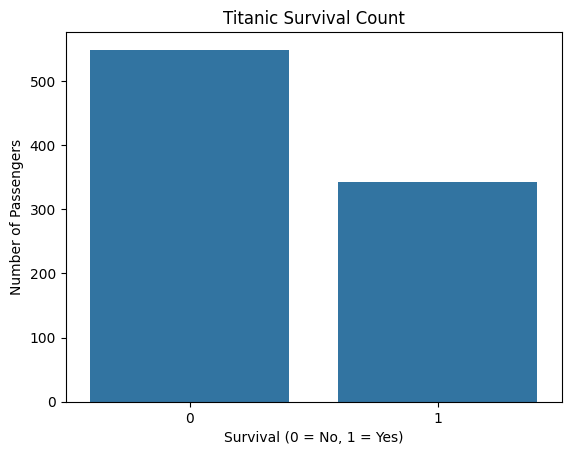

In [4]:
sns.countplot(data=df, x="survived")

plt.title("Titanic Survival Count")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

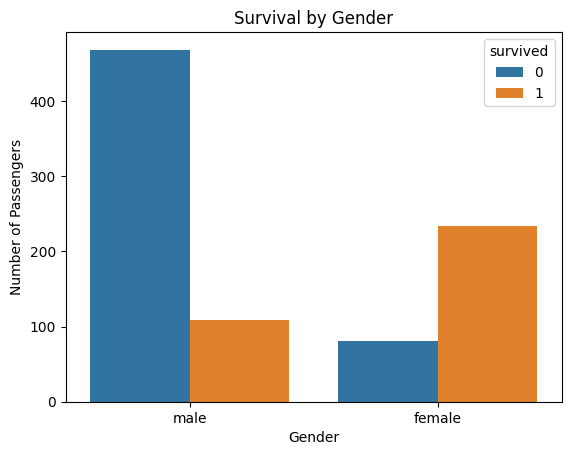

In [5]:
sns.countplot(data=df, x="sex", hue="survived")

plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

In [6]:
# Select features
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]

X = df[features].copy()
y = df["survived"]

# Handle missing numerical values
for col in ["age", "fare"]:
    X[col] = X[col].fillna(X[col].median())

# Handle missing categorical values
X["embarked"] = X["embarked"].fillna(X["embarked"].mode()[0])

# Convert categorical variables into numerical variables
X = pd.get_dummies(X, columns=["sex", "embarked"], drop_first=True, dtype=int)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create the model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [7]:
# Make predictions
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 81.56 %

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.87      0.85       110
           1       0.78      0.72      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



In [8]:
# Create a sample passenger
passenger = pd.DataFrame([{
    "pclass": 1,
    "age": 25,
    "sibsp": 0,
    "parch": 0,
    "fare": 80.0,
    "sex_male": 0,
    "embarked_Q": 0,
    "embarked_S": 0
}])

# Ensure columns match the training data
passenger = passenger.reindex(columns=X_train.columns, fill_value=0)

# Predict survival
prediction = model.predict(passenger)[0]

if prediction == 1:
    print("Prediction: Passenger may have survived.")
else:
    print("Prediction: Passenger may not have survived.")

Prediction: Passenger may have survived.


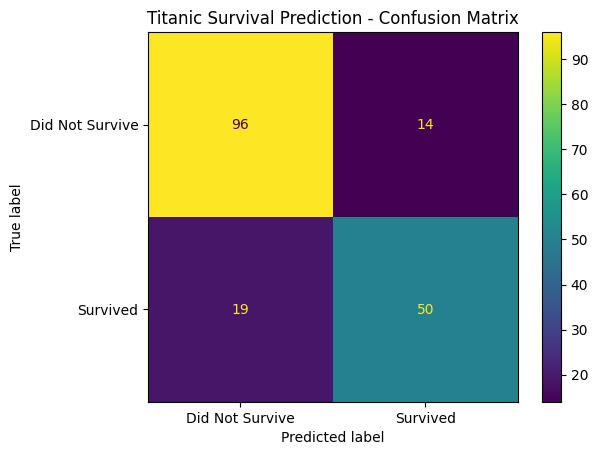

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did Not Survive", "Survived"]
)

display.plot()
plt.title("Titanic Survival Prediction - Confusion Matrix")
plt.show()

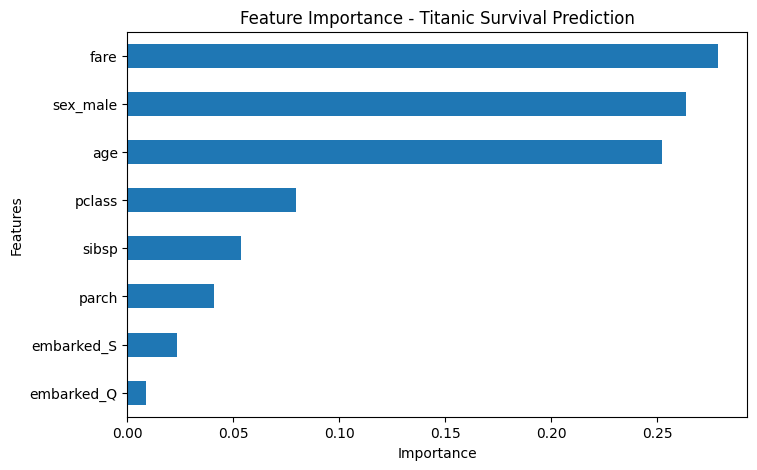

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

importance.plot(kind="barh", figsize=(8, 5))

plt.title("Feature Importance - Titanic Survival Prediction")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.show()

*Conclusion*

The Titanic Survival Prediction project uses machine learning to predict whether passengers survived the Titanic disaster.
The dataset was explored and preprocessed by handling missing values and converting categorical features into numerical representations.
A Random Forest Classifier was trained using passenger information, including age, gender, passenger class, and fare.
The model was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix.

# This project helped demonstrate the practical application of Python, data preprocessing, exploratory data analysis, and machine learning classification.